# Part 5 | Network activity & bursts

Cultures spontaneously produce **network bursts**: brief, synchronised
spiking across the whole network, separated by quiet periods. We find them from
the **population firing rate** (all spikes pooled, binned, smoothed) by flagging
where it rises above a threshold.

## Goal

Detect network bursts and quantify how the network fires together.

By the end of this part you can:
- build the population rate of all curated units
- detect network bursts and see how the detection settings affect them
- compute burst rate, inter-burst interval and its regularity

> **How the exercises work.** You will meet three kinds of boxes:
> - **✎ Your turn** — one line of code to complete: look for `# TODO` and the
>   obviously-wrong placeholder (e.g. `0.0`). The explanation or worked example
>   just above it shows what you need, and a **check** prints `[OK]` when you
>   got it, or a hint if not.
> - **💬 Discuss:** — a question to discuss with your partner. No code, no check.
> - **🔧 Try it:** — an optional experiment: change a value, re-run, and see what
>   happens. Set it back afterwards.
>
> The full answers live in `mea_helpers.py` if you ever want to peek.

In [1]:
# ========================= YOUR SETTINGS ==============================
GROUP_ID  = 5            # your group number
DRUG      = "A"          # "A" or "B"
CONDITION = "Baseline"   # "Baseline" or "Drug"

DATA_ROOT = "../data"             # <-- folder with the .h5 files on THIS laptop
MANIFEST  = "../recordings.csv"      # built during the session
# ======================================================================

import sys; sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import mea_helpers as mea

manifest = mea.load_manifest(MANIFEST)
row = mea.find_recording(manifest, GROUP_ID, DRUG, CONDITION)
print("Selected recording:"); print(row)

Selected recording:
UID                        G05_A_Baseline
GroupID                                 5
Chip                               maxtwo
Drug                                    A
Conditions                       Baseline
Well                                    0
raw_files       raw/G05_A_Baseline.raw.h5
sorted_files        sorted/G05_A_Baseline
Name: 0, dtype: object


## 1. Population rate and burst detection

### Worked example — population rate and burst detection

- **Which units:** only the **curated units**, with the same rule as in Part 3
  (`mea.curate_units`): Kilosort labelled the unit `good` (a clear refractory
  dip in its autocorrelogram) **and** fewer than **1 %** of its inter-spike
  intervals are shorter than **1.5 ms** (the refractory period).
- **Population rate:** all spikes of the curated units are pooled and counted
  in 25 ms bins (`bin_s`), then smoothed over 5 bins (`smooth_bins`), in
  spikes/s.
- **Network burst:** a period where the population rate stays above a
  threshold, here **3 x its median** (`threshold_factor`), for at least
  50 ms (`min_duration_s`). The median is a robust baseline: bursts are
  short, so most of the time the network is between bursts.

225 curated units, 103861 spikes
25 bursts  (threshold 1488.0 spikes/s)


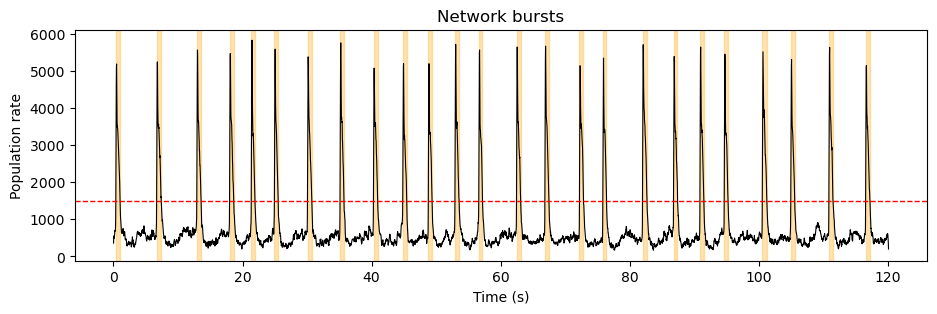

,start,end,duration,peak_rate
0,0.3875,1.0125,0.625,5184.0
1,6.6875,7.3875,0.700,5240.0
2,12.9125,13.5625,0.650,5560.0
3,17.9875,18.6375,0.650,5464.0
4,21.3625,21.8875,0.525,5824.0


In [2]:
recording = mea.open_recording(row, data_root=DATA_ROOT)
duration = recording.get_num_frames() / recording.get_sampling_frequency()
sorting = mea.load_sorting(row, data_root=DATA_ROOT)
spikes = mea.sorting_to_spikes(sorting)
clean = mea.curate_units(mea.unit_features(spikes, duration, sorting=sorting))
spikes = spikes[spikes["unit"].isin(clean.index)]   # curated: 'good' + < 1 % ISIs < 1.5 ms
print(f"{len(clean)} curated units, {len(spikes)} spikes")

t, pop = mea.population_rate(spikes, duration, bin_s=0.025, smooth_bins=5)
bursts, thr = mea.detect_network_bursts(t, pop, threshold_factor=3, min_duration_s=0.05)
print(f"{len(bursts)} bursts  (threshold {thr:.1f} spikes/s)")

plt.figure(figsize=(11, 3))
plt.plot(t, pop, "k", lw=0.8); plt.axhline(thr, color="r", ls="--", lw=1)
for _, b in bursts.iterrows():
    plt.axvspan(b["start"], b["end"], color="orange", alpha=0.3)
plt.xlabel("Time (s)"); plt.ylabel("Population rate"); plt.title("Network bursts")
plt.show()
bursts.head()

> **🔧 Try it:** change `threshold_factor` to 2 and then 5, and `smooth_bins`
> to 1, and re-run. How much does the burst *count* move? (Good to know before
> comparing drugs.) Set them back to 3 and 5 afterwards.

## 2. Firing rate and burst rate

### ✎ Your turn — mean firing rate per unit

`spikes` is the table of all spikes of the curated units (one row per spike),
so `len(spikes)` is the total number of spikes; `n_units` is the number of
units and `duration` the recording length in seconds.

Compute the mean firing rate **per unit**, in Hz: the total number of spikes
divided by the duration **and** by the number of units. Part 6 compares this
value between conditions as `network_rate_hz`.

In [3]:
n_units = spikes["unit"].nunique()

# TODO: replace the 0.0 with the mean firing rate per unit (Hz).
network_rate = 0.0

print(f"{len(spikes)} spikes, {n_units} units, {duration:.0f} s -> {network_rate:.2f} Hz per unit")
mea.check(network_rate, mea.firing_rate(spikes["time"], duration) / n_units,
          hint="network_rate = len(spikes) / duration / n_units")

103861 spikes, 225 units, 120 s -> 0.00 Hz per unit
[X] not quite yet.
   hint: network_rate = len(spikes) / duration / n_units
   you got: 0.0
   expected ~ 3.84478131304718


False

> **💬 Discuss:** how does this per-unit rate compare with the per-channel MUA
> rates from Part 2, and why might they differ?

### ✎ Your turn — burst rate per minute

`n_bursts` bursts happened during the `duration` seconds of the recording.
Compute the **burst rate per minute**: the number of bursts divided by the
duration *in minutes* (60 seconds in a minute).

In [4]:
n_bursts = len(bursts)

# TODO: replace the 0.0 with the number of bursts per minute.
burst_rate_per_min = 0.0

print(f"{n_bursts} bursts in {duration:.0f} s -> {burst_rate_per_min:.1f} per minute")
mea.check(burst_rate_per_min, mea.burst_features(bursts, duration)["burst_rate_per_min"],
          hint="burst_rate_per_min = n_bursts / (duration / 60)")

25 bursts in 120 s -> 0.0 per minute
[X] not quite yet.
   hint: burst_rate_per_min = n_bursts / (duration / 60)
   you got: 0.0
   expected ~ 12.493753123438282


False

## 3. Burst regularity

### ✎ Your turn — inter-burst interval (IBI) and its regularity

The IBI is the quiet gap between one burst's **end** and the next burst's
**start**; the code below computes all of them (`ibi`, in s). How *regular*
is the rhythm? Its **coefficient of variation** tells you:

CV = standard deviation / mean of the IBIs (`ibi.std()` and `ibi.mean()`).

A CV near **0** means bursts come like clockwork; near **1**, as irregularly
as random events.

In [5]:
starts = bursts["start"].to_numpy()
ends   = bursts["end"].to_numpy()
ibi = starts[1:] - ends[:-1]          # gaps between consecutive bursts (s)
print(f"{len(ibi)} IBIs, mean {ibi.mean():.2f} s")

# TODO: replace the 0.0 with the CV of the IBIs.
cv_ibi = 0.0

print(f"CV of the IBI = {cv_ibi:.2f}")
mea.check(cv_ibi, mea.burst_features(bursts, duration)["cv_ibi"],
          hint="cv_ibi = ibi.std() / ibi.mean()")

24 IBIs, mean 4.23 s
CV of the IBI = 0.00
[X] not quite yet.
   hint: cv_ibi = ibi.std() / ibi.mean()
   you got: 0.0
   expected ~ 0.2170799082672585


False

## 4. All burst features at once

In [6]:
n_units = spikes["unit"].nunique()
for k, v in mea.burst_features(bursts, duration, spikes=spikes, n_channels=n_units).items():
    print(f"{k:>24}: {v}")

                n_bursts: 25
      burst_rate_per_min: 12.493753123438282
   mean_burst_duration_s: 0.6120000000000015
              mean_ibi_s: 4.229166666666665
                  cv_ibi: 0.2170799082672585
      mean_participation: 0.8458666666666665
